# 04. Model Training

Quy trình:
1. Baseline: **Logistic Regression** (kèm `StandardScaler`, `class_weight='balanced'`)
2. So sánh: **Random Forest**, **XGBoost**, **LightGBM**
3. Đánh giá: Accuracy, Precision, Recall, F1, ROC-AUC
4. Ưu tiên **Recall** ở lớp churn (mục tiêu: phát hiện tối đa khách hàng có nguy cơ rời bỏ)
5. Lưu model tốt nhất vào `models/churn_pipeline.pkl`

Dữ liệu đã được xử lý ở notebook 03 (`data/processed/`), nên không cần preprocessing lại.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

train = pd.read_csv('../data/processed/train_processed.csv')
test = pd.read_csv('../data/processed/test_processed.csv')

X_train = train.drop(columns=['Churn'])
y_train = train['Churn']
X_test = test.drop(columns=['Churn'])
y_test = test['Churn']

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Churn rate (train):', round(y_train.mean(), 4))

Train: (4504, 38) | Test: (1126, 38)
Churn rate (train): 0.1683


## Bước 1: Baseline — Logistic Regression

- Dùng `StandardScaler` vì Logistic Regression nhạy với thang đo của feature.
- Dùng `class_weight='balanced'` để bù mất cân bằng lớp (churn chỉ ~17%).
- Đây là benchmark để so sánh với các model phức tạp hơn.

In [2]:
def evaluate_model(model, X_test, y_test, name):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob)
    }

# Baseline: Logistic Regression
lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
lr.fit(X_train, y_train)

results = [evaluate_model(lr, X_test, y_test, 'LogisticRegression')]
pd.DataFrame(results).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LogisticRegression,0.8242,0.4879,0.8474,0.6192,0.9043


## Bước 2: Random Forest

Ensemble cây quyết định, ít nhạy với outlier, `class_weight='balanced'` để xử lý mất cân bằng.

In [3]:
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

results.append(evaluate_model(rf, X_test, y_test, 'RandomForest'))
pd.DataFrame(results).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LogisticRegression,0.8242,0.4879,0.8474,0.6192,0.9043
1,RandomForest,0.9751,0.9091,0.9474,0.9278,0.9928


## Bước 3: XGBoost

`scale_pos_weight` = tỷ lệ không-churn/churn (~4.9) để bù mất cân bằng lớp.

In [4]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print('scale_pos_weight:', round(scale_pos_weight, 2))

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=5,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train, y_train)

results.append(evaluate_model(xgb, X_test, y_test, 'XGBoost'))
pd.DataFrame(results).round(4)

scale_pos_weight: 4.94


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LogisticRegression,0.8242,0.4879,0.8474,0.6192,0.9043
1,RandomForest,0.9751,0.9091,0.9474,0.9278,0.9928
2,XGBoost,0.9671,0.8844,0.9263,0.9049,0.9862


## Bước 4: LightGBM

Leaf-wise growth, nhanh và hiệu quả trên dữ liệu dạng bảng.

In [5]:
lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.1,
    num_leaves=31,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)
lgbm.fit(X_train, y_train)

results.append(evaluate_model(lgbm, X_test, y_test, 'LightGBM'))
pd.DataFrame(results).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LogisticRegression,0.8242,0.4879,0.8474,0.6192,0.9043
1,RandomForest,0.9751,0.9091,0.9474,0.9278,0.9928
2,XGBoost,0.9671,0.8844,0.9263,0.9049,0.9862
3,LightGBM,0.9778,0.9231,0.9474,0.9351,0.9930


## Bước 5: So sánh các model

Sắp xếp theo **Recall** (ưu tiên phát hiện khách hàng rời bỏ), tie-break bằng **F1** khi Recall bằng nhau, đồng thời xem Precision để đánh giá độ tin cậy.

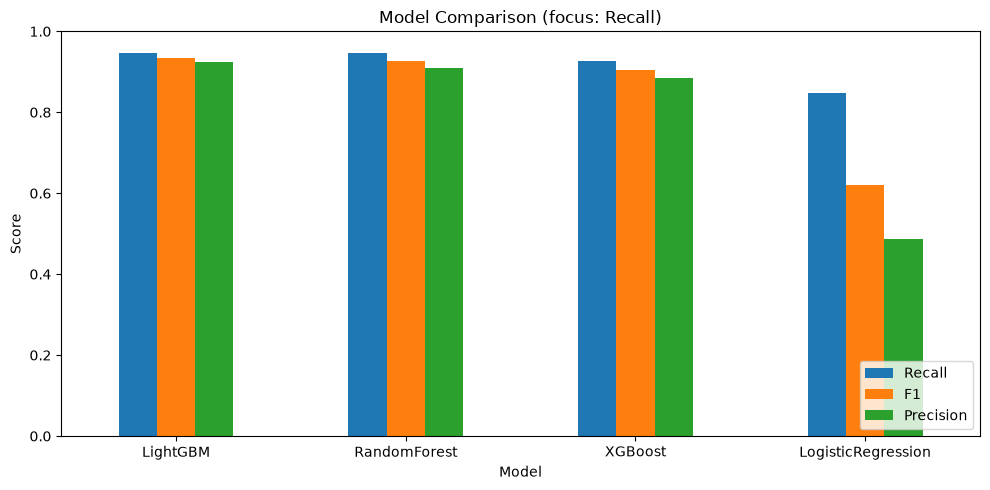

In [6]:
results_df = pd.DataFrame(results).sort_values(['Recall', 'F1'], ascending=False).reset_index(drop=True)
results_df.round(4)

fig, ax = plt.subplots(figsize=(10, 5))
results_df.plot(x='Model', y=['Recall', 'F1', 'Precision'], kind='bar', ax=ax)
plt.title('Model Comparison (focus: Recall)')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Bước 6: Tuning hyperparameter — LightGBM

Dùng `RandomizedSearchCV` (cv=5) trên LightGBM — model đang dẫn đầu.

- `scoring='f1'`: cân bằng Precision và Recall. Nếu dùng `scoring='recall'` pure, model tối ưu Recall đến mức Precision sụt mạnh (overfit recall trên CV).
- `average_precision` (PR-AUC) cho kết quả tương tự F1 trên dữ liệu này.

In [7]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [200, 300, 500, 800],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'num_leaves': [15, 31, 63, 127],
    'max_depth': [3, 5, 7, -1],
    'min_child_samples': [10, 20, 40],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [0, 0.1, 1]
}

lgbm_search = LGBMClassifier(
    class_weight='balanced', random_state=42, verbose=-1
)
search = RandomizedSearchCV(
    lgbm_search, param_dist, n_iter=50,
    scoring='f1', cv=5, random_state=42, n_jobs=-1
)
search.fit(X_train, y_train)

print('Best params:', search.best_params_)
print('Best CV F1:', round(search.best_score_, 4))

lgbm_tuned = search.best_estimator_
results.append(evaluate_model(lgbm_tuned, X_test, y_test, 'LightGBM-Tuned'))
pd.DataFrame(results).round(4)

Best params: {'subsample': 1.0, 'reg_lambda': 0, 'reg_alpha': 0, 'num_leaves': 31, 'n_estimators': 300, 'min_child_samples': 20, 'max_depth': 7, 'learning_rate': 0.2, 'colsample_bytree': 0.6}
Best CV F1: 0.8969


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LogisticRegression,0.8242,0.4879,0.8474,0.6192,0.9043
1,RandomForest,0.9751,0.9091,0.9474,0.9278,0.9928
2,XGBoost,0.9671,0.8844,0.9263,0.9049,0.9862
3,LightGBM,0.9778,0.9231,0.9474,0.9351,0.9930
4,LightGBM-Tuned,0.9796,0.9326,0.9474,0.9399,0.9929


In [8]:
# Lưu model có Recall cao nhất
models = {
    'LogisticRegression': lr,
    'RandomForest': rf,
    'XGBoost': xgb,
    'LightGBM': lgbm,
    'LightGBM-Tuned': lgbm_tuned
}
best_name = results_df.iloc[0]['Model']
best_model = models[best_name]

os.makedirs('../models', exist_ok=True)
joblib.dump(best_model, '../models/churn_pipeline.pkl')
print(f'Model tot nhat (Recall): {best_name}')
print('Da luu: ../models/churn_pipeline.pkl')

Model tot nhat (Recall): LightGBM
Da luu: ../models/churn_pipeline.pkl


## Kết luận

- Logistic Regression là baseline để benchmark.
- So sánh 4 model theo Accuracy, Precision, Recall, F1, ROC-AUC.
- Chọn model có **Recall cao nhất** để lưu vào `models/churn_pipeline.pkl`.
- Nếu muốn cải thiện thêm: tuning hyperparameter (GridSearchCV/RandomizedSearchCV), thử SMOTE (cần thêm `imbalanced-learn`), hoặc bổ sung feature.

Tiếp theo: notebook `05_model_evaluation.ipynb` để đánh giá chi tiết model đã lưu (confusion matrix, ROC curve, PR curve, feature importance).